In [ ]:
!pip install pandas
!pip install numpy
!pip install yfinance

In [ ]:
#from google.colab import drive
#drive.mount('/content/gdrive')

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
import torch
from sklearn.preprocessing import MinMaxScaler
from keras.models import Sequential
from keras.layers import Dense, LSTM
plt.style.use('fivethirtyeight')
import math
import joblib

df = yf.download('BTC-USD', start='2014-12-31', end='2024-06-01', interval='1d')
df

[*********************100%%**********************]  1 of 1 completed


,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
2014-12-31,310.914001,320.192993,310.210999,320.192993,320.192993,13942900
2015-01-01,320.434998,320.434998,314.002991,314.248993,314.248993,8036550
2015-01-02,314.079010,315.838989,313.565002,315.032013,315.032013,7860650
2015-01-03,314.846008,315.149994,281.082001,281.082001,281.082001,33054400
2015-01-04,281.145996,287.230011,257.612000,264.195007,264.195007,55629100
...,...,...,...,...,...,...
2024-05-27,68512.179688,70597.882812,68232.500000,69394.554688,69394.554688,25870990717
2024-05-28,69392.195312,69514.640625,67227.156250,68296.218750,68296.218750,32722265965
2024-05-29,68296.351562,68852.460938,67101.492188,67578.093750,67578.093750,26707072906


In [ ]:
df.shape

(3440, 6)

In [ ]:
from sklearn.preprocessing import MinMaxScaler
import numpy as np

# Data harga Bitcoin (contoh)
bitcoin_prices = np.array([
    [8500, 8700],  # [harga pembukaan, harga penutupan] pada tanggal 1
    [8700, 8800],  # [harga pembukaan, harga penutupan] pada tanggal 2
    [8800, 9000],
    [8800, 9000],
    [8800, 9000],
    [8800, 9000],# [harga pembukaan, harga penutupan] pada tanggal 3
    # ... dan seterusnya
])

# Menginisialisasi MinMaxScaler
scaler = MinMaxScaler()

# Melakukan scaling pada data harga Bitcoin
bitcoin_prices_scaled = scaler.fit_transform(bitcoin_prices)

# Menampilkan data harga Bitcoin yang telah discaling
print(bitcoin_prices_scaled)

[[0.         0.        ]
 [0.66666667 0.33333333]
 [1.         1.        ]
 [1.         1.        ]
 [1.         1.        ]
 [1.         1.        ]]


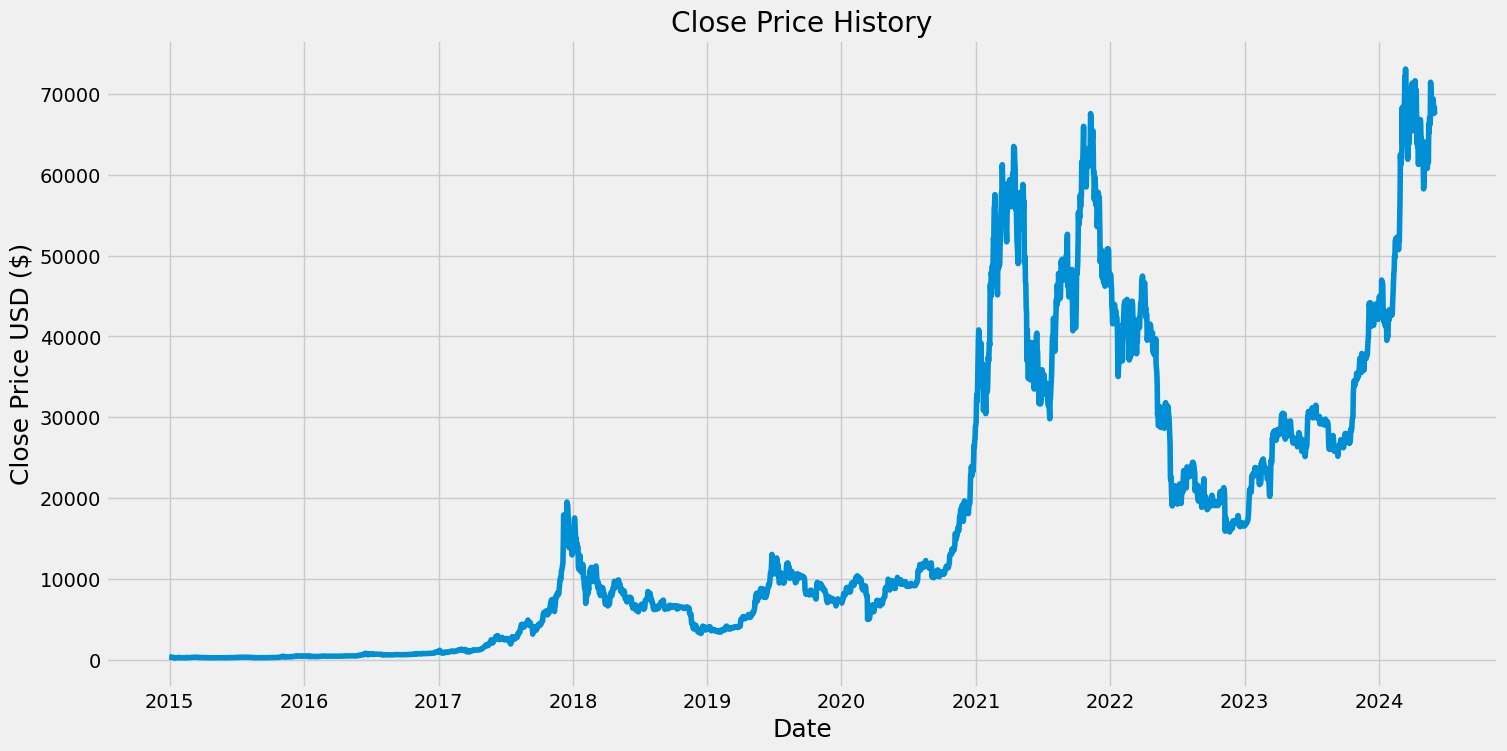

In [ ]:
plt.figure(figsize=(16,8))
plt.title('Close Price History')
plt.plot(df['Close'])
plt.xlabel('Date', fontsize=18)
plt.ylabel('Close Price USD ($)', fontsize=18)
plt.show()

In [ ]:
data = df.filter(['Close'])
dataset = data.values
training_data_len = math.ceil(len(dataset) * .8)
training_data_len

2752

In [ ]:
scaler = MinMaxScaler(feature_range=(0,1))
scaled_data = scaler.fit_transform(dataset)
scaled_data

array([[0.00194896],
       [0.00186743],
       [0.00187817],
       ...,
       [0.92448561],
       [0.93527903],
       [0.92329668]])

In [ ]:
# Ganti 'nama_scaler.pkl' dengan nama file yang Anda inginkan untuk scaler Anda.
joblib.dump(scaler, 'skripsi_scaler.pkl')

['skripsi_scaler.pkl']

In [ ]:
from google.colab import files
files.download('skripsi_scaler.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
#Training data
train_data = scaled_data[0:training_data_len , :]

x_train = []
y_train = []

for i in range(60, len(train_data)):
  x_train.append(train_data[i-60:i, 0])
  y_train.append(train_data[i, 0])

In [ ]:
x_train, y_train = np.array(x_train), np.array(y_train)

In [ ]:
x_train = np.reshape(x_train, (x_train.shape[0], x_train.shape[1], 1))
x_train.shape

(2692, 60, 1)

In [ ]:
from sklearn.metrics import f1_score
from keras.callbacks import Callback

In [ ]:
import tensorflow as tf
from keras import backend as K
# F1 Score Callback
# F1 Score Callback
def f1_score_callback(y_true, y_pred):
    y_pred_binary = tf.cast(tf.greater(y_pred, 0.5), tf.float32)  # Ensure y_pred_binary has float32 type
    y_true = tf.cast(y_true, tf.float32)  # Convert y_true to float32
    f1 = 2 * tf.reduce_sum(y_true * y_pred_binary) / (tf.reduce_sum(y_true) + tf.reduce_sum(y_pred_binary) + K.epsilon())
    return f1

In [ ]:
#LSTM
model = Sequential()
model.add(LSTM(50, return_sequences=True, input_shape = (x_train.shape[1], 1)))
model.add(LSTM(50, return_sequences=False))
model.add(Dense(25))
model.add(Dense(1))

In [ ]:
model.compile(optimizer='adam', loss='mean_squared_error', metrics=['accuracy'])

In [ ]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm (LSTM)                 (None, 60, 50)            10400     
                                                                 
 lstm_1 (LSTM)               (None, 50)                20200     
                                                                 
 dense (Dense)               (None, 25)                1275      
                                                                 
 dense_1 (Dense)             (None, 1)                 26        
                                                                 
Total params: 31901 (124.61 KB)
Trainable params: 31901 (124.61 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [ ]:
history = model.fit(x_train, y_train, batch_size=256, epochs=70)

Epoch 1/70
11/11 [==============================] - 3s 305ms/step - loss: 1.3674e-04 - accuracy: 0.0000e+00
Epoch 2/70
11/11 [==============================] - 2s 225ms/step - loss: 1.3239e-04 - accuracy: 0.0000e+00
Epoch 3/70
11/11 [==============================] - 3s 291ms/step - loss: 1.3256e-04 - accuracy: 0.0000e+00
Epoch 4/70
11/11 [==============================] - 4s 325ms/step - loss: 1.3465e-04 - accuracy: 0.0000e+00
Epoch 5/70
11/11 [==============================] - 2s 209ms/step - loss: 1.3069e-04 - accuracy: 0.0000e+00
Epoch 6/70
11/11 [==============================] - 2s 216ms/step - loss: 1.3042e-04 - accuracy: 0.0000e+00
Epoch 7/70
11/11 [==============================] - 2s 211ms/step - loss: 1.2981e-04 - accuracy: 0.0000e+00
Epoch 8/70
11/11 [==============================] - 2s 225ms/step - loss: 1.3115e-04 - accuracy: 0.0000e+00
Epoch 9/70
11/11 [==============================] - 4s 358ms/step - loss: 1.3155e-04 - accuracy: 0.0000e+00
Epoch 10/70
11/11 [=========

In [ ]:
test_data = scaled_data[training_data_len - 60: , :]
x_test = []
y_test = dataset[training_data_len:, :]
for i in range(60, len(test_data)):
  x_test.append(test_data[i-60:i, 0])

In [ ]:
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping


In [ ]:
x_test = np.array(x_test)

In [ ]:
x_test = np.reshape(x_test, (x_test.shape[0], x_test.shape[1], 1))

In [ ]:
#Prediksi
predictions = model.predict(x_test)
predictions = scaler.inverse_transform(predictions)

22/22 [==============================] - 0s 18ms/step


In [ ]:
#Root Mean Squared Error
rmse = np.sqrt(np.mean(predictions - y_test)**2 )
rmse

100.28911643804506

In [ ]:
model.save('lstm_forecast_real.h5')

/usr/local/lib/python3.10/dist-packages/keras/src/engine/training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


In [ ]:
from google.colab import files
files.download('lstm_forecast_real.h5')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<ipython-input-53-dbfac1cda5f1>:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  valid['Predictions'] = predictions


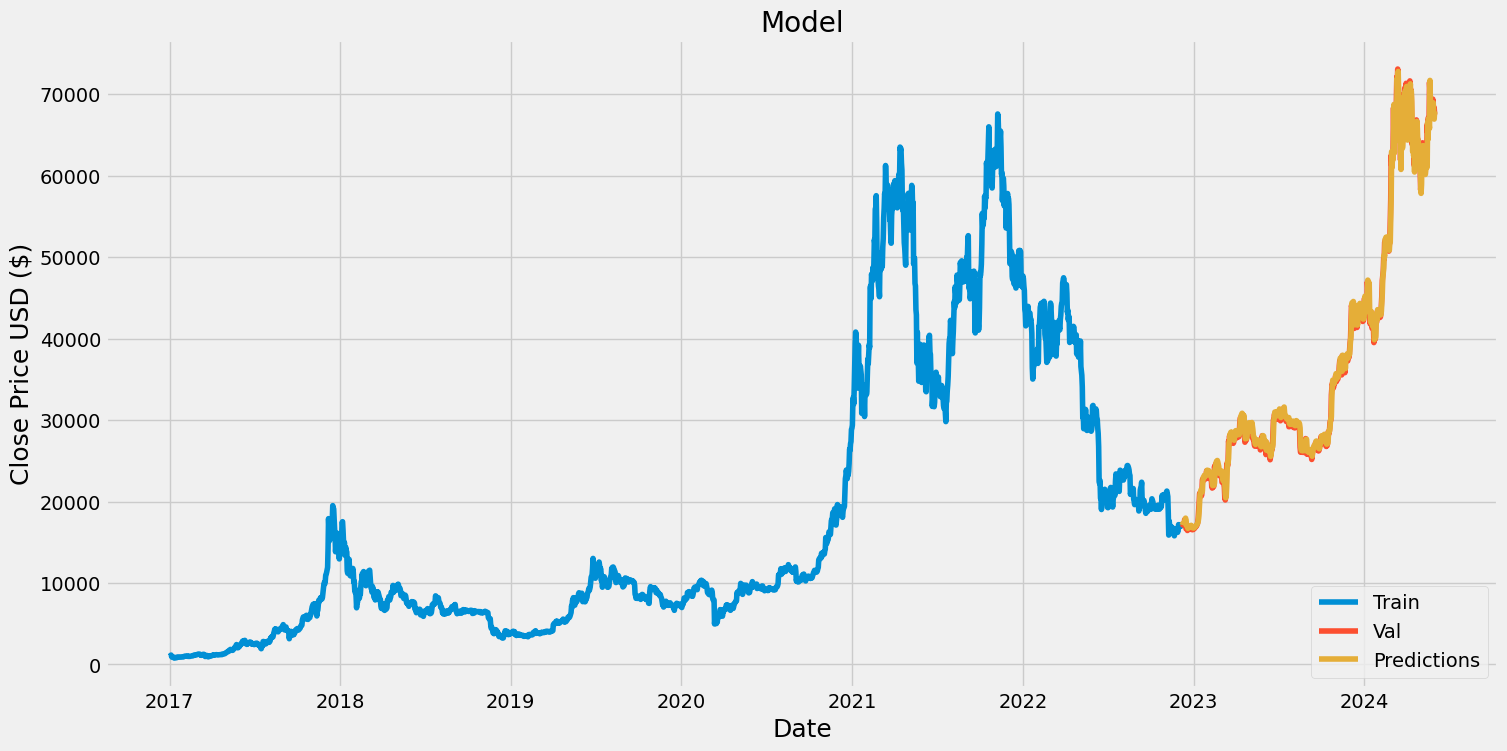

In [ ]:
#Plot
train = data[:training_data_len]
valid = data[training_data_len:]
valid['Predictions'] = predictions

plt.figure(figsize=(16,8))
plt.title('Model')
plt.xlabel('Date', fontsize=18)
plt.ylabel('Close Price USD ($)', fontsize=18)
plt.plot(train['Close'])
plt.plot(valid[['Close', 'Predictions']])
plt.legend(['Train', 'Val','Predictions'], loc='lower right')
plt.show()

In [ ]:
valid

,Close,Predictions
Date,,
2022-12-08,17233.474609,17107.439453
2022-12-09,17133.152344,17305.630859
2022-12-10,17128.724609,17324.742188
2022-12-11,17104.193359,17319.070312
2022-12-12,17206.437500,17298.111328
...,...,...
2024-05-27,69394.554688,67730.593750
2024-05-28,68296.218750,68933.656250
2024-05-29,67578.093750,67401.648438


In [ ]:
bitcoin_quote = yf.download('BTC-USD', start='2022-01-01', end='2024-06-11')
new_df = bitcoin_quote.filter(['Close'])
last_60_days = new_df[-60:].values
last_60_days_scaled = scaler.transform(last_60_days)
X_test =[]
X_test.append(last_60_days_scaled)
X_test = np.array(X_test)
X_test = np.reshape(X_test, (X_test.shape[0], X_test.shape[1], 1))
pred_price = model.predict(X_test)
pred_price = scaler.inverse_transform(pred_price)
print(pred_price)

[*********************100%%**********************]  1 of 1 completed

1/1 [==============================] - 0s 26ms/step
[[68794.82]]


In [ ]:
df2 = yf.download('BTC-USD', start='2010-01-01', end='2024-06-12', interval='1d')
df2

[*********************100%%**********************]  1 of 1 completed


,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
2014-09-17,465.864014,468.174011,452.421997,457.334015,457.334015,21056800
2014-09-18,456.859985,456.859985,413.104004,424.440002,424.440002,34483200
2014-09-19,424.102997,427.834991,384.532013,394.795990,394.795990,37919700
2014-09-20,394.673004,423.295990,389.882996,408.903992,408.903992,36863600
2014-09-21,408.084991,412.425995,393.181000,398.821014,398.821014,26580100
...,...,...,...,...,...,...
2024-06-06,71082.843750,71625.734375,70119.125000,70757.164062,70757.164062,25223152007
2024-06-07,70759.187500,71907.851562,68507.257812,69342.585938,69342.585938,36188381096
2024-06-08,69324.179688,69533.320312,69210.742188,69305.773438,69305.773438,14262185861


In [ ]:
#Root Mean Squared Error
rmse = np.sqrt(np.mean(predictions - y_test)**2 )
rmse

1474.907422766838